In [1]:
# Cell 1: 依赖库导入 / Import Dependencies
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

# Mesa 核心组件导入 (适配 Mesa 3.x 及以上版本) / Import Mesa Core Components (Compatible with Mesa 3.x+)
import mesa
from mesa import Agent, Model
from mesa.space import SingleGrid
from mesa.datacollection import DataCollector

# 设置随机种子以保证实验可复现性（调试时可用，若要随机可设为 None） / Set random seed for reproducibility (useful for debugging, set to None for randomness)
RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

print(f"✅ Cell 1: 依赖库导入完成，Mesa 版本 / Dependencies loaded, Mesa version: {mesa.__version__}")

✅ Cell 1: 依赖库导入完成，Mesa 版本 / Dependencies loaded, Mesa version: 3.3.1


In [2]:
# Cell 2: 全局超级参数配置中心 / Global Super Parameter Configuration Center
# ==============================================================================
# 1. 空间与地图参数 (Environment & Spatial Config)
# ==============================================================================
GRID_WIDTH = 100               # 网格宽度 (X轴) / Grid Width (X-axis)
GRID_HEIGHT = 100              # 网格高度 (Y轴) / Grid Height (Y-axis)
EAST_BOUNDARY_X = 50           # 东部高资源区划分线 (X >= 50 为东部) / Eastern high-resource area boundary (X >= 50 is East)

RESOURCE_SPAWN_PROB = 0.08     # 每一轮全图每个空格子刷新资源的概率 / Probability of spawning resources on an empty grid cell per step
BASE_RESOURCE_VAL = 10         # 西部(左侧)空格子刷新的基础资源量 / Base resource amount spawned in the Western (left) empty cells
EAST_RESOURCE_MULTIPLIER = 1.5 # 东部(右侧)资源的倍率 n (例如 1.5 代表多 50% 资源) / Resource multiplier n for Eastern (right) cells (e.g., 1.5 means 50% more resources)
TECH_BOOST_RATIO = 0.20        # 科学发现触发后，全局资源刷新上限的提升比例 (+20%) / Global resource spawn limit boost ratio upon tech discovery (+20%)

# ==============================================================================
# 2. Population 规模与五类人格初始配置 (Population & Archetype Distribution)
# ==============================================================================
INIT_AGENTS_COUNT = 100        # 初始生成的 Agent 总数 / Initial total number of Agents

# 五类人格在初始种群中的分布比例权重 (占比之和不要求强行等于1，系统会自动归一化) 
# Distribution ratio weights of five archetypes in initial population (Sum doesn't need to be 1; system auto-normalizes)
ARCHETYPE_RATIOS = {
    "Social_Darwinist": 0.15,   # 社会达尔文主义者 / Social Darwinist
    "Moral_Artist":     0.15,   # 道德表演艺术家 / Moral Artist
    "Ruffian":          0.15,   # 打手 / 暴徒 / Ruffian
    "Mob":              0.45,   # 庸众 / 暴民 / Mob
    "Hermit_Sage":      0.10    # 隐士 / 智者 / Hermit Sage
}

# 五类人格的属性点分配基准 [Int, Inf, Mor, Imp_V, Exp_V, Exp_T] / Archetype base stats benchmark [Int, Inf, Mor, Imp_V, Exp_V, Exp_T]
# 数值范围: [0, 100]，在生成 Agent 时会在此基准上叠加 ±5 的随机浮动 / Value range: [0, 100], ±5 random variation will be added when generating Agents
ARCHETYPE_BASE_STATS = {
    "Social_Darwinist": {"int": 85, "inf": 80, "mor": 20, "imp_v": 90, "exp_v": 15, "exp_t": 40},
    "Moral_Artist":     {"int": 60, "inf": 90, "mor": 30, "imp_v": 20, "exp_v": 5,  "exp_t": 20},
    "Ruffian":          {"int": 30, "inf": 30, "mor": 10, "imp_v": 30, "exp_v": 90, "exp_t": 5},
    "Mob":              {"int": 40, "inf": 40, "mor": 50, "imp_v": 40, "exp_v": 40, "exp_t": 15},
    "Hermit_Sage":      {"int": 90, "inf": 20, "mor": 80, "imp_v": 5,  "exp_v": 5,  "exp_t": 90}
}

# ==============================================================================
# 3. 生存、生命周期与移动参数 (Survival, Lifecycle & Movement)
# ==============================================================================
INIT_RESOURCE_PER_AGENT = 100  # Agent 创角时的初始资源量 / Initial resource amount per Agent upon creation
BASE_CONSUMPTION = 2           # 每个 Agent 每一轮固定的基础生存消耗 (C_base) / Fixed base survival consumption per Agent per step (C_base)
MOVE_STEP_LIMIT = 5            # Agent 每一轮可移动的最长曼哈顿距离 (5 或 10 格) / Max Manhattan distance an Agent can move per step (5 or 10 grids)

STARVE_LIMIT_STEPS = 10        # 资源 <= 0 后，连续饿肚子 N 轮则破产死亡 / Starve for N consecutive steps after resources <= 0 results in death
RETIRE_AGE_STEPS = 200        # 自然衰老起点轮数 (50岁，假设 4 轮/岁) / Natural aging starting step (Age 50, assuming 4 steps/year)
OLD_AGE_DEATH_PROB = 0.01      # 超过 60 岁后，每一轮按此基础概率递增衰老死亡 / Base incremental probability of dying from old age after age 60 per step

# ==============================================================================
# 4. Phase 1 局部资源争夺与 Phase 2 进阶动作参数 (Phase 1 & Phase 2 Game Engine)
# ==============================================================================
# Phase 1 局部 3x3 网格竞拍的智力与影响力权重 / Intelligence and Influence weights for local 3x3 grid auction in Phase 1
WEIGHT_INT_RATIO = 0.6         # 竞拍权重中智力的比重 / Weight ratio of Intelligence in auction
WEIGHT_INF_RATIO = 0.4         # 竞拍权重中影响力的比重 / Weight ratio of Influence in auction

# Phase 2 掠夺机制参数 / Phase 2 Plunder mechanism parameters
STEAL_BASE_RATIO = 0.3         # 掠夺成功时，默认基础掠夺对方资产的比例 (30%) / Default base proportion of target assets plundered on success (30%)
EXPLICIT_VIOLENCE_CRIT_MULT = 2.0 # 显性暴力触发暴击时掠夺量翻倍系数 / Critical hit multiplier for plunder amount during explicit violence
PUNISH_PROB_EXPLICIT = 0.30    # 高显性暴力行为触发“法律/集体反抗”惩罚的概率 / Probability of triggering "law/collective resistance" punishment for high explicit violence
PUNISH_PENALTY_RATIO = 0.50    # 触发法律惩罚时，一次性扣除当前资产的比例 (50%) / One-time deduction ratio of current assets when legal punishment is triggered (50%)

# Phase 2 科学发现/科研参数 / Phase 2 Scientific discovery & research parameters
TECH_PROGRESS_THRESHOLD = 500  # 全局科研进度条蓄满阈值，蓄满即触发一次科学发现 / Global research progress bar threshold; fills up to trigger a scientific discovery

# ==============================================================================
# 5. Phase 3 社会关系参数 (Phase 3 Social Interactions)
# ==============================================================================
# 婚姻与繁殖 / Marriage and Reproduction
MARRY_RESOURCE_MIN = 150       # 发起结婚的最低个人资源门槛 / Minimum personal resource threshold to propose marriage
BREED_RESOURCE_MIN = 300       # 夫妻总资源达到此阈值可触发繁殖 / Total couple resources required to trigger reproduction
BREED_COST_RATIO = 0.30        # 繁殖时扣除夫妻总资产的 30% 作为抚养费 / Deduction ratio of couple's total assets for child-rearing cost during reproduction (30%)
DIVORCE_COOLDOWN_STEPS = 50    # 离婚后的再婚冷却期 (轮数) / Remarriage cooldown period after divorce (in steps)
GENIUS_MUTATION_PROB = 0.01    # 子代产生单一属性爆表 (+30) 的天才突变概率 / Probability of genius mutation (+30 in single stat) for offspring

# 联盟与内耗 / Alliance and Internal Friction
MAX_ALLIANCE_MEMBERS = 8       # 一个小团体/联盟的最大人数上限 / Maximum member capacity for a group or alliance
ALLIANCE_BASE_COST = 1.0       # 联盟基础维护费 (每多一人按 Size^1.5 增加) / Alliance base maintenance cost (Increases by Size^1.5 for each additional member)
ALLIANCE_MORAL_FRICTION = 0.05 # 联盟内部成员道德差值产生的内耗扣减系数 / Internal friction deduction coefficient caused by moral differences among alliance members

# 追随者与保护伞 / Followers and Protection Umbrella
PROTECTION_FEE_RATIO = 0.10    # 追随者每轮上缴给保护者/联盟的资源比例 α (10%) / Resource fee ratio α paid by followers to protector/alliance each step (10%)
PROTECTION_DEFENSE_FACTOR = 0.90# 追随者受到掠夺时，借用保护者属性的折扣系数 (90%) / Discount factor for borrowing protector's stats when a follower is plundered (90%)
FAILURE_REPUTATION_PENALTY = 5.0# 保护伞保护失败时，保护者 Influence 永久下降值 / Permanent Influence penalty for protector when umbrella protection fails

print("✅ Cell 2: 全局超级参数配置中心载入成功！所有变量已注册。 / Global Super Parameter Configuration Center loaded successfully! All variables registered.")

✅ Cell 2: 全局超级参数配置中心载入成功！所有变量已注册。 / Global Super Parameter Configuration Center loaded successfully! All variables registered.


In [3]:
# Cell 3: 社交网络与信息通讯数据结构 / Social Network & Information Communication Data Structures
# ==============================================================================

class SocialNetwork:
    """
    维护 Agent 之间的社交图谱，处理信息共享、信任度以及关系拓扑
    关系类型包括: 'marriage' (婚姻), 'alliance' (联盟), 'kinship' (亲属), 'follower' (追随)
    
    Maintains the social graph between Agents, handling information sharing, trust levels, and relational topology.
    Relation types include: 'marriage', 'alliance', 'kinship', 'follower'
    """
    def __init__(self):
        self.graph = nx.Graph()

    def add_agent(self, agent_id):
        """将 Agent 注册到社交网络 / Register Agent to the social network"""
        if not self.graph.has_node(agent_id):
            self.graph.add_node(agent_id)

    def remove_agent(self, agent_id):
        """Agent 死亡时从网络中移除 / Remove Agent from network upon death"""
        if self.graph.has_node(agent_id):
            self.graph.remove_node(agent_id)

    def add_relation(self, agent_a_id, agent_b_id, relation_type):
        """添加或更新关系 / Add or update relationship"""
        self.add_agent(agent_a_id)
        self.add_agent(agent_b_id)
        self.graph.add_edge(agent_a_id, agent_b_id, type=relation_type)

    def remove_relation(self, agent_a_id, agent_b_id, relation_type=None):
        """移除指定关系 / Remove specified relationship"""
        if self.graph.has_edge(agent_a_id, agent_b_id):
            if relation_type is None or self.graph[agent_a_id][agent_b_id].get('type') == relation_type:
                self.graph.remove_edge(agent_a_id, agent_b_id)

    def get_relatives_and_allies(self, agent_id):
        """获取强社交圈（配偶、盟友、父母与子女），用于信息共享广播 / Get inner social circle (spouses, allies, parents & children) for information broadcasting"""
        if not self.graph.has_node(agent_id):
            return []
        
        close_ids = []
        for neighbor in self.graph.neighbors(agent_id):
            edge_type = self.graph[agent_id][neighbor].get('type')
            if edge_type in ['marriage', 'alliance', 'kinship']:
                close_ids.append(neighbor)
        return close_ids

    def broadcast_resource_info(self, source_agent, target_pos, model):
        """
        关系圈“信息通讯”补丁:
        当 source_agent 发现高浓度资源格时，向配偶、盟友和直系亲属广播坐标
        
        Relational Circle "Information Communication" Patch:
        Broadcasts coordinates to spouse, allies, and immediate family when source_agent discovers high-density resource cells.
        """
        close_ids = self.get_relatives_and_allies(source_agent.unique_id)
        for target_id in close_ids:
            # 找到对应的 Agent 对象并更新其“记忆导航目标” / Find corresponding Agent object and update its "memory navigation target"
            if target_id in model.agents_dict:
                ally = model.agents_dict[target_id]
                # 只有当对方当前没有更优目标时才更新导航目标 / Update navigation target only if the ally currently has no better target
                if ally.known_high_resource_pos is None:
                    ally.known_high_resource_pos = target_pos

print("✅ Cell 3: 社交网络与信息通讯模块载入成功！ / Social Network & Information Communication module loaded successfully!")

✅ Cell 3: 社交网络与信息通讯模块载入成功！ / Social Network & Information Communication module loaded successfully!


In [4]:
# Cell 4: Agent 核心类定义 (SocialAgent) - 修复版 / Agent Core Class Definition (SocialAgent) - Fixed Version
# ==============================================================================
import warnings
warnings.filterwarnings("ignore", category=UserWarning, module="mesa") # 屏蔽 Mesa 内部重复放置的非致命提示 / Suppress non-fatal warning messages from Mesa internal duplicate placements

class SocialAgent(Agent):
    """
    具备 6 维属性向量、状态机与三阶段动作流的智能体
    Agent equipped with a 6-dimensional attribute vector, state machine, and three-stage action pipeline.
    """
    def __init__(self, model, archetype, pos=None):
        super().__init__(model)
        self.archetype = archetype  # 人格类型名 / Archetype name
        
        # 1. 资源与生命周期初始化 / 1. Resources and Lifecycle Initialization
        self.resources = INIT_RESOURCE_PER_AGENT
        self.age = 0                # 年龄（轮数） / Age (in steps)
        self.starve_steps = 0       # 连续饥饿轮数 / Consecutive starving steps
        self.is_alive = True
        
        # 2. 6 维核心属性向量 (基础值 + 随机浮动 ±5，限制在 [1, 100]) / 2. 6D Core Attribute Vector (Base value + random fluctuation ±5, clipped to [1, 100])
        base_stats = ARCHETYPE_BASE_STATS[archetype]
        self.int = int(np.clip(base_stats["int"] + random.randint(-5, 5), 1, 100))
        self.inf = int(np.clip(base_stats["inf"] + random.randint(-5, 5), 1, 100))
        self.mor = int(np.clip(base_stats["mor"] + random.randint(-5, 5), 1, 100))
        self.imp_v = int(np.clip(base_stats["imp_v"] + random.randint(-5, 5), 1, 100))
        self.exp_v = int(np.clip(base_stats["exp_v"] + random.randint(-5, 5), 1, 100))
        self.exp_t = int(np.clip(base_stats["exp_t"] + random.randint(-5, 5), 1, 100))

        # 3. 社交状态标记 / 3. Social State Flags
        self.spouse_id = None            # 配偶 unique_id / Spouse unique_id
        self.divorce_cooldown = 0        # 离婚冷却期 / Divorce cooldown period
        self.alliance_id = None          # 所属联盟 ID / Alliance ID
        self.leader_id = None            # 追随的大佬 unique_id / Leader unique_id followed
        self.followers = []              # 追随自己的 follower unique_id 列表 / List of follower unique_ids
        self.children = []               # 子女 unique_id 列表 / List of children unique_ids
        self.parents = []                # 父母 unique_id 列表 / List of parents unique_ids
        
        # 4. 导航记忆与 Buff 状态 / 4. Navigation Memory & Buff States
        self.known_high_resource_pos = None  # 共享获取的高资源格坐标 / Coordinates of high-resource cell obtained via sharing

    # --------------------------------------------------------------------------
    # 属性与 Buff 动态计算 / Dynamic Calculation of Attributes & Buffs
    # --------------------------------------------------------------------------
    @property
    def effective_int(self):
        """婚姻协同 Buff: 低属性方获得配偶溢出加成 (婚姻期间有效) / Marriage Synergy Buff: Lower-stat spouse receives overflow bonus (Active during marriage)"""
        bonus = 0
        if self.spouse_id and self.spouse_id in self.model.agents_dict:
            spouse = self.model.agents_dict[self.spouse_id]
            if spouse.int > self.int:
                bonus = int((spouse.int - self.int) * 0.3)
        return min(100, self.int + bonus)

    @property
    def effective_inf(self):
        """婚姻协同 Buff: 影响力加成 / Marriage Synergy Buff: Influence Bonus"""
        bonus = 0
        if self.spouse_id and self.spouse_id in self.model.agents_dict:
            spouse = self.model.agents_dict[self.spouse_id]
            if spouse.inf > self.inf:
                bonus = int((spouse.inf - self.inf) * 0.3)
        return min(100, self.inf + bonus)

    # --------------------------------------------------------------------------
    # 行为偏好计算 / Behavioral Preference Calculations
    # --------------------------------------------------------------------------
    def get_explore_preference(self):
        """
        计算 Phase 2 选择【探索】还是【掠夺】的概率 / Calculate probability of choosing [Explore] vs [Plunder] in Phase 2
        P(探索 / Explore) = Exploration / (Exploration + 100 - Morality)
        """
        explore_score = self.exp_t
        predate_score = (100 - self.mor) + 0.1  # 防止分母为 0 / Prevent division by zero
        p_explore = explore_score / (explore_score + predate_score)
        return p_explore

    def get_auction_weight(self):
        """Phase 1 局部 3x3 竞拍争夺权重: Int * 0.6 + Inf * 0.4 / Phase 1 local 3x3 auction competition weight: Int * 0.6 + Inf * 0.4"""
        return self.effective_int * WEIGHT_INT_RATIO + self.effective_inf * WEIGHT_INF_RATIO

    # --------------------------------------------------------------------------
    # 周期状态更新 / Lifecycle State Updates
    # --------------------------------------------------------------------------
    def update_lifecycle(self):
        """每一轮更新年龄、消耗生存资源以及冷却状态 / Update age, consume survival resources, and update cooldown states each step"""
        self.age += 1
        self.resources -= BASE_CONSUMPTION
        
        # 扣减离婚冷却时间 / Deduct divorce cooldown time
        if self.divorce_cooldown > 0:
            self.divorce_cooldown -= 1
            
        # 检查饥饿状态 / Check starvation state
        if self.resources <= 0:
            self.starve_steps += 1
        else:
            self.starve_steps = 0  # 恢复正常 / Reset to normal

print("✅ Cell 4: SocialAgent 核心类修复完成！ / SocialAgent core class fixed successfully!")

✅ Cell 4: SocialAgent 核心类修复完成！ / SocialAgent core class fixed successfully!


In [5]:
# Cell 5: Agent 三阶段动作逻辑实现 - 修复 UnboundLocalError / Agent Three-Stage Action Logic Implementation - Fixed UnboundLocalError
# ==============================================================================

def agent_phase_1_move_and_collect(self):
    """Phase 1: 导航移动与局部 3x3 资源竞拍 / Navigation movement and local 3x3 resource auction"""
    if not self.is_alive or self.pos is None:
        return

    # 1.1 寻路导航策略 (优先向共享导航点移动，否则向东部高资源区移动)
    # Pathfinding navigation strategy (Prioritize moving towards shared target, otherwise move towards Eastern high-resource area)
    target_pos = None
    if self.known_high_resource_pos:
        target_pos = self.known_high_resource_pos
    elif self.pos[0] < EAST_BOUNDARY_X:
        target_pos = (random.randint(EAST_BOUNDARY_X, GRID_WIDTH - 1), random.randint(0, GRID_HEIGHT - 1))

    # 在 MOVE_STEP_LIMIT 曼哈顿距离内选择最优移动位置 / Select optimal movement position within MOVE_STEP_LIMIT Manhattan distance
    possible_steps = self.model.grid.get_neighborhood(
        self.pos, moore=True, include_center=True, radius=MOVE_STEP_LIMIT
    )
    empty_steps = [p for p in possible_steps if self.model.grid.is_cell_empty(p) or p == self.pos]

    if empty_steps:
        if target_pos:
            best_step = min(empty_steps, key=lambda p: abs(p[0]-target_pos[0]) + abs(p[1]-target_pos[1]))
        else:
            best_step = random.choice(empty_steps)
        
        if best_step != self.pos:
            self.model.grid.move_agent(self, best_step)

    # 到达目的地后重置导航目标 / Reset navigation target upon arrival
    if self.known_high_resource_pos and self.pos == self.known_high_resource_pos:
        self.known_high_resource_pos = None

    # 1.2 局部 3x3 资源竞拍收集 / Local 3x3 resource auction collection
    neighbors_3x3 = self.model.grid.get_neighborhood(self.pos, moore=True, include_center=True, radius=1)
    for cell in neighbors_3x3:
        # 修复关键点：提取 grid_res 到最外层，确保变量始终存在 / Key fix: Extract grid_res to outer scope to ensure variable always exists
        grid_res = self.model.grid_resources.get(cell, 0)
        
        if grid_res > 0:
            cell_agents = [a for a in self.model.grid.get_cell_list_contents(cell) if a.is_alive]
            if cell_agents:
                total_weight = sum(a.get_auction_weight() for a in cell_agents)
                if total_weight > 0:
                    my_share = grid_res * (self.get_auction_weight() / total_weight)
                    self.resources += my_share
                    
                    # 清空/扣减该格资源（由最后一个处理的 agent 清空） / Clear/deduct cell resource (Cleared by the last processed agent)
                    if self == cell_agents[-1]:
                        self.model.grid_resources[cell] = 0

            # 信息广播补丁：只有格子里确实有高资源时才广播 / Info broadcast patch: Broadcast only when cell actually has high resources
            if grid_res >= BASE_RESOURCE_VAL * 2:
                self.model.social_net.broadcast_resource_info(self, cell, self.model)

def agent_phase_2_game_action(self):
    """Phase 2: 进阶动作（探索发现 vs 尝试掠夺） / Advanced Actions (Exploration & Research vs Attempted Plunder)"""
    if not self.is_alive or self.pos is None:
        return

    p_explore = self.get_explore_preference()
    if random.random() < p_explore:
        # --- 选项 A: 探索科研 / Option A: Exploration & Research ---
        tech_contrib = (self.effective_int * self.exp_t) / 100.0
        self.model.global_tech_progress += tech_contrib
    else:
        # --- 选项 B: 尝试掠夺 / Option B: Attempt Plunder ---
        neighbors = self.model.grid.get_neighbors(self.pos, moore=True, include_center=False, radius=1)
        potential_victims = [
            a for a in neighbors if a.is_alive 
            and a.unique_id != self.spouse_id 
            and a.alliance_id != self.alliance_id
            and a.leader_id != self.unique_id
        ]
        
        if potential_victims:
            victim = min(potential_victims, key=lambda a: a.effective_int) # 挑选最弱者 / Select the weakest target
            
            victim_def_stat = victim.effective_int
            protector = None
            if victim.leader_id and victim.leader_id in self.model.agents_dict:
                protector = self.model.agents_dict[victim.leader_id]
                victim_def_stat = max(victim.effective_int, int(protector.effective_int * PROTECTION_DEFENSE_FACTOR))

            my_attack = self.effective_int + self.imp_v
            if my_attack > victim_def_stat:
                steal_ratio = STEAL_BASE_RATIO * (1.0 - self.mor / 100.0)
                if random.random() < (self.exp_v / 100.0):
                    steal_ratio *= EXPLICIT_VIOLENCE_CRIT_MULT
                
                stolen_amount = victim.resources * steal_ratio
                victim.resources -= stolen_amount
                self.resources += stolen_amount

                if protector and victim_def_stat > victim.effective_int:
                    protector.inf = max(1, protector.inf - FAILURE_REPUTATION_PENALTY)

            if random.random() < (self.exp_v / 100.0) * PUNISH_PROB_EXPLICIT:
                penalty = self.resources * PUNISH_PENALTY_RATIO
                self.resources -= penalty

def agent_phase_3_social_action(self):
    """Phase 3: 社会关系动作 (婚姻/离婚/结盟/追随) / Social Interactions (Marriage / Divorce / Alliance / Follow)"""
    if not self.is_alive or self.pos is None:
        return

    # 3.1 离婚检查 / 3.1 Divorce Check
    if self.spouse_id and self.spouse_id in self.model.agents_dict:
        spouse = self.model.agents_dict[self.spouse_id]
        if self.mor < 30 and (self.resources < spouse.resources * 0.3):
            self.model.social_net.remove_relation(self.unique_id, self.spouse_id, 'marriage')
            spouse.spouse_id = None
            self.spouse_id = None
            self.divorce_cooldown = DIVORCE_COOLDOWN_STEPS
            spouse.divorce_cooldown = DIVORCE_COOLDOWN_STEPS
            total_res = self.resources + spouse.resources
            self.resources = total_res / 2.0
            spouse.resources = total_res / 2.0
            
            # 补丁：记录离婚事件 / Patch: Record divorce event
            self.model.step_events["divorces"] += 1

    # 3.2 结婚与繁殖检查 / 3.2 Marriage and Reproduction Check
    if not self.spouse_id and self.divorce_cooldown == 0 and self.resources >= MARRY_RESOURCE_MIN:
        neighbors = self.model.grid.get_neighbors(self.pos, moore=True, include_center=False, radius=1)
        single_candidates = [
            a for a in neighbors if a.is_alive and not a.spouse_id 
            and a.divorce_cooldown == 0 and a.resources >= MARRY_RESOURCE_MIN
        ]
        if single_candidates:
            partner = random.choice(single_candidates)
            self.spouse_id = partner.unique_id
            partner.spouse_id = self.unique_id
            self.model.social_net.add_relation(self.unique_id, partner.unique_id, 'marriage')
            
            # 补丁：记录结婚事件 / Patch: Record marriage event
            self.model.step_events["marriages"] += 1

    # 已婚则判定繁殖 / If married, check for reproduction
    if self.spouse_id and self.spouse_id in self.model.agents_dict:
        spouse = self.model.agents_dict[self.spouse_id]
        if (self.resources + spouse.resources) >= BREED_RESOURCE_MIN:
            cost = (self.resources + spouse.resources) * BREED_COST_RATIO
            self.resources -= cost / 2.0
            spouse.resources -= cost / 2.0
            self.model.breed_child(self, spouse)

    # 3.3 追随者上缴保护费 / 3.3 Followers Pay Protection Fee
    if self.leader_id and self.leader_id in self.model.agents_dict:
        leader = self.model.agents_dict[self.leader_id]
        fee = self.resources * PROTECTION_FEE_RATIO
        self.resources -= fee
        leader.resources += fee
    elif not self.leader_id and self.inf < 40 and not self.alliance_id:
        neighbors = self.model.grid.get_neighbors(self.pos, moore=True, include_center=False, radius=2)
        leaders = [a for a in neighbors if a.is_alive and a.inf >= 70 and a.unique_id != self.unique_id]
        if leaders:
            big_boss = max(leaders, key=lambda a: a.inf)
            self.leader_id = big_boss.unique_id
            big_boss.followers.append(self.unique_id)
            self.model.social_net.add_relation(self.unique_id, big_boss.unique_id, 'follower')

# 挂载方法 / Mount Methods
SocialAgent.phase_1_move_and_collect = agent_phase_1_move_and_collect
SocialAgent.phase_2_game_action = agent_phase_2_game_action
SocialAgent.phase_3_social_action = agent_phase_3_social_action

print("✅ Cell 5: 作用域与安全检查修复完成！ / Scope and safety check fix completed!")

✅ Cell 5: 作用域与安全检查修复完成！ / Scope and safety check fix completed!


In [6]:
# Cell 6: 主模型类定义 (SocialModel) - 集成计算社会学全景数据指标统计
# Cell 6: Main Model Class Definition (SocialModel) - Integrated Computational Sociology Metrics Statistics
# ==============================================================================

class SocialModel(Model):
    """
    仿真主控模型: 负责网格刷新、技术突破、生老病死清算与社会学全景数据统计
    Master Simulation Model: Responsible for grid updates, tech breakthroughs, lifecycle events, and computational sociology metrics.
    """
    def __init__(self):
        super().__init__()
        self.grid = SingleGrid(GRID_WIDTH, GRID_HEIGHT, torus=False)
        self.social_net = SocialNetwork()
        
        # 状态索引与跟踪 / State Indexing & Tracking
        self.agents_dict = {}
        self.grid_resources = {}          # (x, y) -> 资源量 / Resource Amount
        self.global_tech_progress = 0     # 全局科研进度 / Global Scientific Research Progress
        self.tech_boost_active = False    # 是否触发了科学突破 Buff / Whether Tech Breakthrough Buff is Triggered
        self.alliance_counter = 0         # 联盟编号分配器 / Alliance ID Allocator
        self.step_count = 0               # 运行轮数计数器 / Simulation Step Counter

        # ----------------------------------------------------------------------
        # 新增：社会动态事件统计追踪器（单轮与累积）
        # New: Social Dynamic Events Tracker (Per Step & Cumulative)
        # ----------------------------------------------------------------------
        self.step_events = {
            "marriages": 0,
            "divorces": 0,
            "defections": 0,       # 追随者背叛/脱离 / Followers Defection/Separation
            "births": 0,
            "deaths_starve": 0,
            "deaths_age": 0
        }
        
        # 按人格分类的科研贡献累积 / Cumulative Scientific Contributions by Archetype
        self.tech_contrib_by_archetype = {
            "Social_Darwinist": 0.0,
            "Moral_Artist": 0.0,
            "Ruffian": 0.0,
            "Mob": 0.0,
            "Hermit_Sage": 0.0
        }

        # 1. 按比例初始化 Agent 并散布地图 / 1. Initialize Agents by Ratios and Scatter on Grid
        archetypes = list(ARCHETYPE_RATIOS.keys())
        weights = list(ARCHETYPE_RATIOS.values())
        norm_weights = [w / sum(weights) for w in weights]

        # 预先获取全图所有可用坐标并打乱 / Pre-fetch all Available Positions and Shuffle
        all_positions = [(x, y) for x in range(GRID_WIDTH) for y in range(GRID_HEIGHT)]
        random.shuffle(all_positions)

        for i in range(min(INIT_AGENTS_COUNT, len(all_positions))):
            arch = np.random.choice(archetypes, p=norm_weights)
            pos = all_positions[i]  # 安全分配不重复的格子 / Safely Assign Unique Grid Cell
            
            agent = SocialAgent(self, arch, pos)
            self.grid.place_agent(agent, pos)
            self.agents_dict[agent.unique_id] = agent
            self.social_net.add_agent(agent.unique_id)

    def get_random_empty_pos(self):
        """
        兼容 Mesa 各版本的安全空格子查找工具函数
        Safe Empty Grid Cell Lookup Helper Function (Compatible with Mesa Versions)
        """
        if hasattr(self.grid, 'empties') and self.grid.empties:
            return random.choice(list(self.grid.empties))
        
        empty_cells = [
            (x, y) for x in range(GRID_WIDTH) for y in range(GRID_HEIGHT) 
            if self.grid.is_cell_empty((x, y))
        ]
        return random.choice(empty_cells) if empty_cells else None

    def spawn_resources(self):
        """
        非对称地图资源刷新机制
        Asymmetric Map Resource Spawning Mechanism
        """
        tech_multiplier = (1.0 + TECH_BOOST_RATIO) if self.tech_boost_active else 1.0
        
        for x in range(GRID_WIDTH):
            for y in range(GRID_HEIGHT):
                if self.grid.is_cell_empty((x, y)):
                    if random.random() < RESOURCE_SPAWN_PROB:
                        base_val = BASE_RESOURCE_VAL
                        if x >= EAST_BOUNDARY_X:
                            base_val *= EAST_RESOURCE_MULTIPLIER
                        
                        spawn_amount = base_val * tech_multiplier * random.uniform(0.8, 1.2)
                        self.grid_resources[(x, y)] = self.grid_resources.get((x, y), 0) + spawn_amount

    def breed_child(self, parent1, parent2):
        """
        生成子代 Agent 并进行遗传与突变
        Spawn Child Agent with Inheritance and Mutation
        """
        empty_pos = self.get_random_empty_pos()
        if not empty_pos:
            return  # 网格全满无法生育 / Cannot Breed When Grid is Full
            
        child_arch = random.choice([parent1.archetype, parent2.archetype, "Mob"])
        child = SocialAgent(self, child_arch, empty_pos)
        
        # 属性遗传 / Attribute Inheritance
        stats = ["int", "inf", "mor", "imp_v", "exp_v", "exp_t"]
        for stat in stats:
            p1_val = getattr(parent1, stat)
            p2_val = getattr(parent2, stat)
            inherited = int((p1_val + p2_val) / 2.0 + random.randint(-10, 10))
            
            if random.random() < GENIUS_MUTATION_PROB:
                inherited += 30
                
            setattr(child, stat, int(np.clip(inherited, 1, 100)))

        # 维护亲属关系网络 / Maintain Kinship Network
        parent1.children.append(child.unique_id)
        parent2.children.append(child.unique_id)
        child.parents = [parent1.unique_id, parent2.unique_id]
        self.social_net.add_relation(parent1.unique_id, child.unique_id, 'kinship')
        self.social_net.add_relation(parent2.unique_id, child.unique_id, 'kinship')

        self.grid.place_agent(child, empty_pos)
        self.agents_dict[child.unique_id] = child
        self.step_events["births"] += 1

    def handle_death_and_inheritance(self, agent, cause="starve"):
        """
        处理破产饿死/老死与财产继承
        Handle Death (Starvation/Old Age) and Estate Inheritance
        """
        agent.is_alive = False
        self.grid.remove_agent(agent)
        
        if cause == "starve":
            self.step_events["deaths_starve"] += 1
        else:
            self.step_events["deaths_age"] += 1

        # 补丁：解绑配偶关系，让遗孀/寡夫恢复单身状态
        # Patch: Unbind Spousal Relationship, Restoring Surviving Spouse to Single Status
        if agent.spouse_id and agent.spouse_id in self.agents_dict:
            spouse = self.agents_dict[agent.spouse_id]
            spouse.spouse_id = None
            self.social_net.remove_relation(agent.unique_id, agent.unique_id, 'marriage')

        # 遗产分配逻辑：平分给配偶与子女 / Inheritance Allocation Logic: Divide Equally Among Spouse and Children
        beneficiaries = []
        if agent.spouse_id and agent.spouse_id in self.agents_dict and self.agents_dict[agent.spouse_id].is_alive:
            beneficiaries.append(self.agents_dict[agent.spouse_id])
        for cid in agent.children:
            if cid in self.agents_dict and self.agents_dict[cid].is_alive:
                beneficiaries.append(self.agents_dict[cid])

        if beneficiaries and agent.resources > 0:
            share = agent.resources / len(beneficiaries)
            for b in beneficiaries:
                b.resources += share

        # 清理社交追随关系 / Clean Up Social Leadership/Follower Relationships
        if agent.leader_id and agent.leader_id in self.agents_dict:
            leader = self.agents_dict[agent.leader_id]
            if agent.unique_id in leader.followers:
                leader.followers.remove(agent.unique_id)

        # 从网络和字典中注销 / Unregister from Network and Dictionary
        self.social_net.remove_agent(agent.unique_id)
        del self.agents_dict[agent.unique_id]

    # --------------------------------------------------------------------------
    # 核心新增：计算社会学全景指标提取器
    # Core Addition: Computational Sociology Metrics Extractor
    # --------------------------------------------------------------------------
    def collect_social_metrics(self):
        """
        计算当前轮次的社会面貌全景数据
        Calculate Computational Sociology Metrics for Current Step
        """
        active_agents = [a for a in self.agents_dict.values() if a.is_alive]
        total_pop = len(active_agents)
        if total_pop == 0:
            return {}

        # 1. 财富与权力分布（基尼系数） / 1. Wealth & Power Distribution (Gini Coefficient)
        resources = sorted([a.resources for a in active_agents])
        follower_counts = sorted([len(a.followers) for a in active_agents])
        
        def calc_gini(array):
            array = np.asarray(array, dtype=np.float64)
            if array.size == 0 or np.sum(array) == 0:
                return 0.0
            array = np.sort(array)
            n = len(array)
            index = np.arange(1, n + 1)
            return float((np.sum((2 * index - n - 1) * array)) / (n * np.sum(array)))

        gini_wealth = calc_gini(np.array(resources))
        gini_power = calc_gini(np.array(follower_counts))

        # 2. 统治阶级与政治团体分析 / 2. Ruling Class & Political Group Analysis
        leaders = [a for a in active_agents if len(a.followers) > 0]
        leaders.sort(key=lambda a: len(a.followers), reverse=True)
        top_5_leaders = leaders[:5]

        leader_archetype_counts = {k: 0 for k in ARCHETYPE_RATIOS.keys()}
        for l in leaders:
            leader_archetype_counts[l.archetype] += 1

        top_leader_info = None
        if top_5_leaders:
            big_boss = top_5_leaders[0]
            top_leader_info = {
                "id": big_boss.unique_id,
                "archetype": big_boss.archetype,
                "followers": len(big_boss.followers),
                "power_share": len(big_boss.followers) / total_pop
            }

        # 3. 人口结构与财富占有率 / 3. Demographic Structure & Wealth Share
        arch_pop = {k: 0 for k in ARCHETYPE_RATIOS.keys()}
        arch_wealth = {k: 0.0 for k in ARCHETYPE_RATIOS.keys()}
        total_wealth = sum(resources)

        for a in active_agents:
            arch_pop[a.archetype] += 1
            arch_wealth[a.archetype] += a.resources

        arch_pop_share = {k: v / total_pop for k, v in arch_pop.items()}
        arch_wealth_share = {k: (v / total_wealth if total_wealth > 0 else 0) for k, v in arch_wealth.items()}

        # 4. 婚姻结构 / 4. Marital Structure
        married_count = sum(1 for a in active_agents if a.spouse_id is not None)
        marriage_rate = (married_count / 2) / total_pop
        celibacy_rate = sum(1 for a in active_agents if a.spouse_id is None and a.resources < MARRY_RESOURCE_MIN) / total_pop

        # 5. 科研贡献率 / 5. Scientific Research Contribution Share
        total_tech = sum(self.tech_contrib_by_archetype.values())
        tech_share = {
            k: (v / total_tech if total_tech > 0 else 0) 
            for k, v in self.tech_contrib_by_archetype.items()
        }

        return {
            "step": self.step_count,
            "total_pop": total_pop,
            "gini_wealth": gini_wealth,
            "gini_power": gini_power,
            "arch_pop_share": arch_pop_share,
            "arch_wealth_share": arch_wealth_share,
            "leaders_count": len(leaders),
            "leader_archetype_counts": leader_archetype_counts,
            "top_leader": top_leader_info,
            "marriage_rate": marriage_rate,
            "celibacy_rate": celibacy_rate,
            "tech_share": tech_share,
            "step_events": dict(self.step_events)
        }

    def print_social_report(self):
        """
        在控制台打印精美社会诊断报告
        Print Social Panoramic Diagnostic Report to Console
        """
        m = self.collect_social_metrics()
        if not m:
            print("⚠️ 当前无存活人口。 / No surviving population currently.")
            return

        print("\n" + "="*80)
        print(f"📊 第 {m['step']} 轮 社会面貌全景诊断报告 / Step {m['step']} Social Panoramic Diagnostic Report")
        print("="*80)
        print(f"【人口与结构 / Demographics & Structure】 存活人口 / Living Pop: {m['total_pop']} | 财富基尼 / Wealth Gini: {m['gini_wealth']:.3f} | 权力基尼 / Power Gini: {m['gini_power']:.3f}")
        
        # 政治与领袖 / Politics & Leaders
        print(f"【政治与权谋 / Politics & Power】 政治领袖数 / Political Leaders: {m['leaders_count']} 人 / agents")
        if m['top_leader']:
            tl = m['top_leader']
            print(f"  - 👑 头号大佬 / Top Leader: Agent_{tl['id']} ({tl['archetype']}) | 追随者 / Followers: {tl['followers']} 人 / agents (控盘 / Control {tl['power_share']*100:.1f}% 人口 / Pop)")
        print(f"  - 统治阶级分布 / Ruling Class Distribution: {m['leader_archetype_counts']}")
        print(f"  - 本轮事件 / Step Events: 结婚 / Marriages {m['step_events']['marriages']}对 / pairs | 离婚 / Divorces {m['step_events']['divorces']}对 / pairs | 饿死 / Starved {m['step_events']['deaths_starve']}人 / agents")

        # 人口与财富对比 / Class & Wealth Comparison
        print("【阶级与财富 / Class & Wealth】")
        for k in ARCHETYPE_RATIOS.keys():
            pop_s = m['arch_pop_share'][k] * 100
            w_s = m['arch_wealth_share'][k] * 100
            t_s = m['tech_share'][k] * 100
            print(f"  - {k:<18}: 人口占 / Pop {pop_s:5.1f}% | 财富占 / Wealth {w_s:5.1f}% | 科研贡献 / Tech Contrib {t_s:5.1f}%")
        print("="*80 + "\n")

    def step(self):
        """
        时钟推进一轮 (1 Step)
        Advance Simulation Clock by One Step
        """
        self.step_count += 1
        
        # 重置单轮事件统计 / Reset Per-Step Event Tracker
        for k in self.step_events:
            self.step_events[k] = 0

        # 1. 刷新环境资源 / 1. Spawn Environmental Resources
        self.spawn_resources()

        # 2. 检查科学发现进度 / 2. Check Scientific Progress
        if self.global_tech_progress >= TECH_PROGRESS_THRESHOLD:
            self.tech_boost_active = True

        # 获取所有活着的 Agent 引用 / Get References to All Active Agents
        active_agents = [a for a in list(self.agents_dict.values()) if a.is_alive]
        random.shuffle(active_agents)

        # 3. 依次调度 Agent 执行 Phase 1, Phase 2, Phase 3
        # 3. Sequentially Schedule Agents to Execute Phase 1, Phase 2, and Phase 3
        for agent in active_agents:
            agent.update_lifecycle()
            agent.phase_1_move_and_collect()

        for agent in active_agents:
            # 记录科研贡献 / Record Scientific Research Contribution
            old_tech = self.global_tech_progress
            agent.phase_2_game_action()
            tech_delta = self.global_tech_progress - old_tech
            if tech_delta > 0:
                self.tech_contrib_by_archetype[agent.archetype] += tech_delta

        for agent in active_agents:
            agent.phase_3_social_action()

        # 4. 死亡清算 / 4. Handle Mortality Clearings
        for agent in active_agents:
            if agent.starve_steps >= STARVE_LIMIT_STEPS:
                self.handle_death_and_inheritance(agent, cause="starve")
            elif agent.age >= RETIRE_AGE_STEPS:
                death_prob = OLD_AGE_DEATH_PROB * (1 + (agent.age - RETIRE_AGE_STEPS) / 100.0)
                if random.random() < death_prob:
                    self.handle_death_and_inheritance(agent, cause="age")

print("✅ Cell 6: 主模型 SocialModel（计算社会学增强版）载入成功！ / Cell 6: Main Model SocialModel (Computational Sociology Enhanced) Loaded Successfully!")

✅ Cell 6: 主模型 SocialModel（计算社会学增强版）载入成功！ / Cell 6: Main Model SocialModel (Computational Sociology Enhanced) Loaded Successfully!


In [7]:
# Cell 7: DataCollector 数据统计与指标计算
# Cell 7: DataCollector Data Statistics and Metrics Calculation
# ==============================================================================

def compute_gini(model):
    """
    计算当前活着 Agent 的财富基尼系数 (Gini Coefficient)
    Calculate Wealth Gini Coefficient for Currently Living Agents
    """
    resources = [a.resources for a in model.agents_dict.values() if a.is_alive and a.resources > 0]
    if not resources or len(resources) < 2:
        return 0.0
    
    array = np.array(resources, dtype=np.float64)
    array = np.sort(array)
    index = np.arange(1, array.shape[0] + 1)
    n = array.shape[0]
    return float((np.sum((2 * index - n - 1) * array)) / (n * np.sum(array)))

def compute_total_wealth(model):
    """
    计算社会总财富量
    Calculate Total Society Wealth
    """
    return sum(a.resources for a in model.agents_dict.values() if a.is_alive)

def compute_archetype_counts(model):
    """
    统计当前各人格类型的存活数量
    Count Currently Living Population for Each Archetype
    """
    counts = {arch: 0 for arch in ARCHETYPE_RATIOS.keys()}
    for a in model.agents_dict.values():
        if a.is_alive:
            counts[a.archetype] = counts.get(a.archetype, 0) + 1
    return counts

def attach_datacollector(model):
    """
    为模型绑定 Mesa DataCollector 数据收集器
    Attach Mesa DataCollector to the Model
    """
    model.datacollector = DataCollector(
        model_reporters={
            "Gini": compute_gini,
            "Total_Wealth": compute_total_wealth,
            "Tech_Progress": lambda m: m.global_tech_progress,
            "Population": lambda m: len([a for a in m.agents_dict.values() if a.is_alive]),
            "Social_Darwinist_Count": lambda m: compute_archetype_counts(m)["Social_Darwinist"],
            "Moral_Artist_Count": lambda m: compute_archetype_counts(m)["Moral_Artist"],
            "Ruffian_Count": lambda m: compute_archetype_counts(m)["Ruffian"],
            "Mob_Count": lambda m: compute_archetype_counts(m)["Mob"],
            "Hermit_Sage_Count": lambda m: compute_archetype_counts(m)["Hermit_Sage"],
        }
    )

print("✅ Cell 7: 数据统计与 Gini 计算模块挂载成功！ / Cell 7: Data Statistics and Gini Calculation Module Loaded Successfully!")

✅ Cell 7: 数据统计与 Gini 计算模块挂载成功！ / Cell 7: Data Statistics and Gini Calculation Module Loaded Successfully!


In [8]:
# Cell 8: 模型实例化与仿真运行
# Cell 8: Model Instantiation and Simulation Run
# ==============================================================================

# 1. 实例化模型并绑定数据收集器（如适用）
# 1. Instantiate Model and Attach DataCollector (if applicable)
model = SocialModel()
if 'attach_datacollector' in globals():
    attach_datacollector(model)

# 2. 运行仿真引擎 (默认运行 500 轮)
# 2. Run Simulation Engine (Default: 500 Steps)
TOTAL_STEPS = 500
print(f"🚀 开始启动社会仿真引擎，计划运行 {TOTAL_STEPS} 轮... / Starting Social Simulation Engine, Planning for {TOTAL_STEPS} Steps...\n")

# 准备历史数据追踪器（用于细粒度绘图）
# Prepare Historical Data Trackers (for fine-grained plotting)
history_power_gini = []
history_top_leader_power = []

for step in range(1, TOTAL_STEPS + 1):
    model.step()
    if hasattr(model, 'datacollector'):
        model.datacollector.collect(model)
    
    # 记录政治演化历史
    # Track Political Evolution History
    metrics = model.collect_social_metrics()
    history_power_gini.append(metrics.get('gini_power', 0.0))
    top_p = metrics['top_leader']['power_share'] if metrics.get('top_leader') else 0.0
    history_top_leader_power.append(top_p)
    
    # 每 100 轮打印一次计算社会学全景诊断报告
    # Print Social Diagnostic Report Every 100 Steps
    if step % 100 == 0:
        model.print_social_report()

print("✨ 仿真运行完成！可以运行下一个 Cell 生成可视化仪表盘。 / Simulation Execution Complete! Ready to Run Next Cell for Visual Dashboard.")

🚀 开始启动社会仿真引擎，计划运行 500 轮... / Starting Social Simulation Engine, Planning for 500 Steps...


📊 第 100 轮 社会面貌全景诊断报告 / Step 100 Social Panoramic Diagnostic Report
【人口与结构 / Demographics & Structure】 存活人口 / Living Pop: 4473 | 财富基尼 / Wealth Gini: 0.321 | 权力基尼 / Power Gini: 0.991
【政治与权谋 / Politics & Power】 政治领袖数 / Political Leaders: 45 人 / agents
  - 👑 头号大佬 / Top Leader: Agent_11 (Social_Darwinist) | 追随者 / Followers: 4 人 / agents (控盘 / Control 0.1% 人口 / Pop)
  - 统治阶级分布 / Ruling Class Distribution: {'Social_Darwinist': 13, 'Moral_Artist': 10, 'Ruffian': 0, 'Mob': 20, 'Hermit_Sage': 2}
  - 本轮事件 / Step Events: 结婚 / Marriages 10对 / pairs | 离婚 / Divorces 2对 / pairs | 饿死 / Starved 7人 / agents
【阶级与财富 / Class & Wealth】
  - Social_Darwinist  : 人口占 / Pop   9.3% | 财富占 / Wealth  11.2% | 科研贡献 / Tech Contrib  12.7%
  - Moral_Artist      : 人口占 / Pop   5.3% | 财富占 / Wealth   6.1% | 科研贡献 / Tech Contrib   5.3%
  - Ruffian           : 人口占 / Pop   1.2% | 财富占 / Wealth   0.9% | 科研贡献 / Tech Contrib   0.8%
  - Mob    

📊 正在生成计算社会学全景数据分析仪表盘... / Generating Computational Sociology Dashboard...


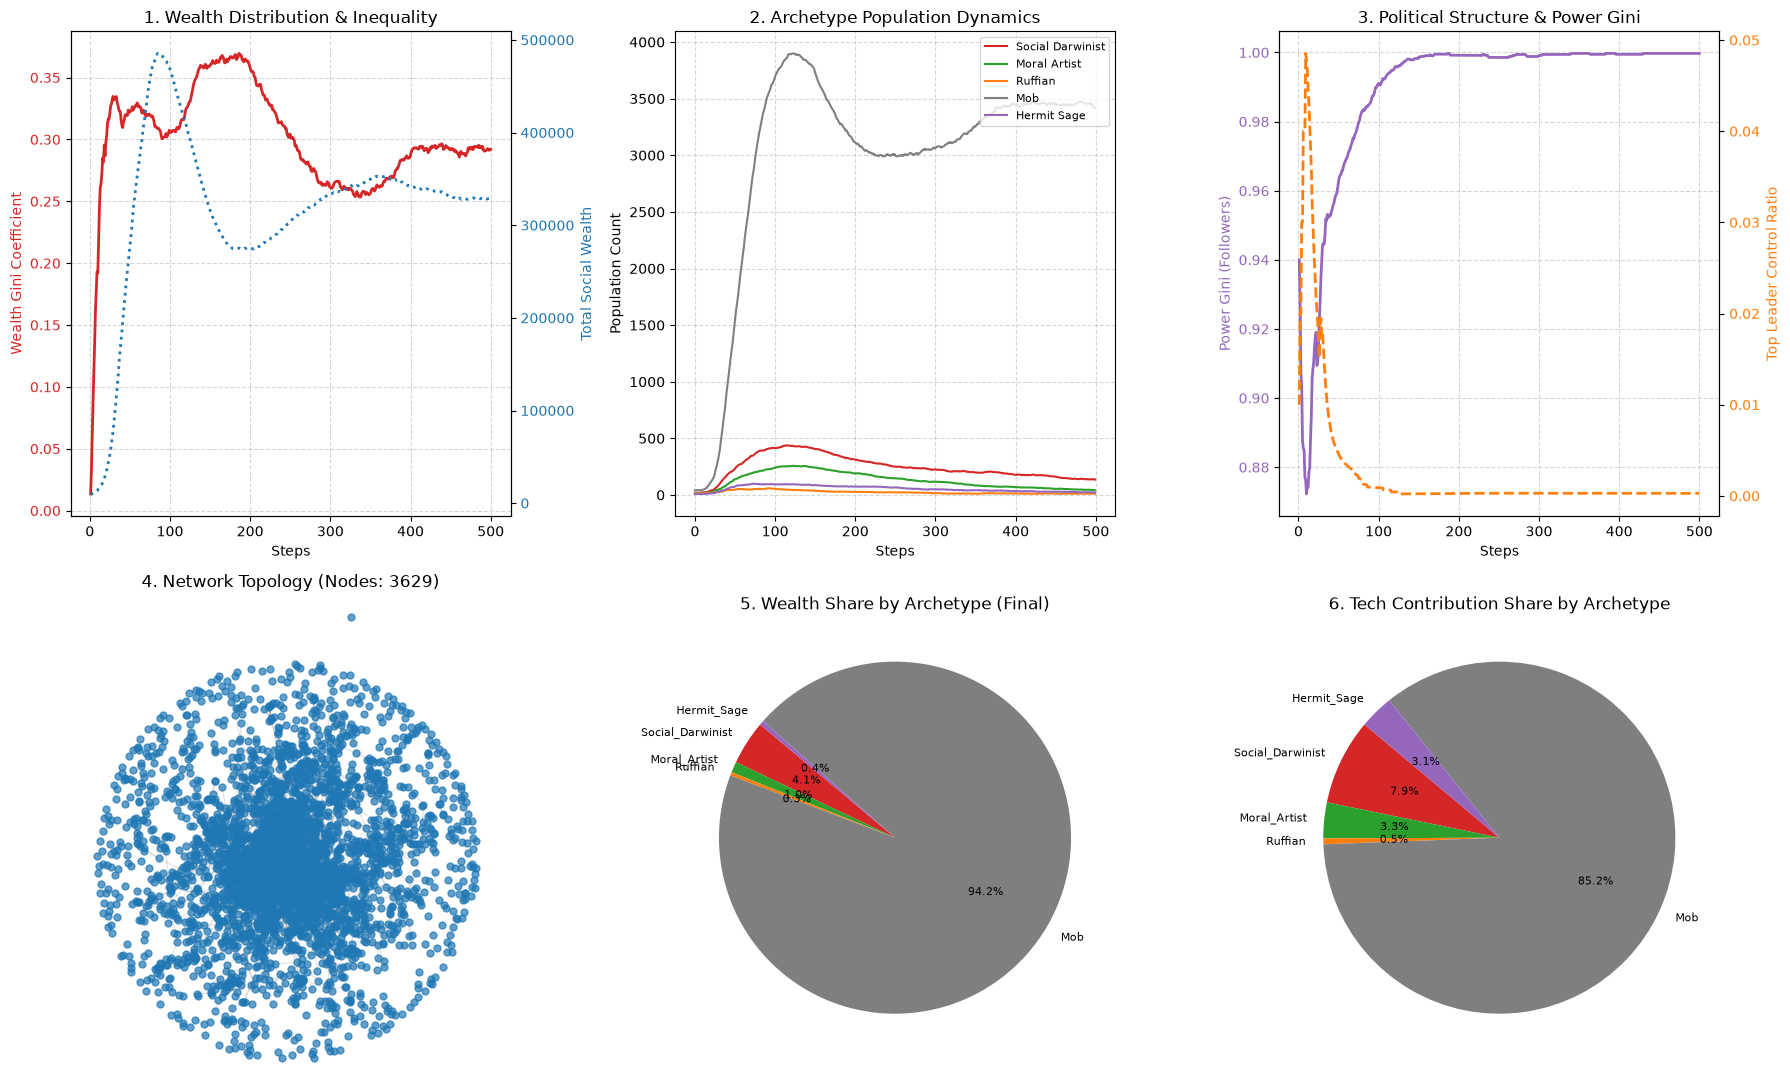

✅ Cell 9: 全景计算社会学仪表盘生成完毕！全流程完美运行。 / Cell 9: Computational Sociology Dashboard Generated Successfully! Entire Workflow Completed.


In [9]:
# Cell 9: 计算社会学全景数据分析仪表盘
# Cell 9: Computational Sociology Panoramic Data Analysis Dashboard
# ==============================================================================

print("📊 正在生成计算社会学全景数据分析仪表盘... / Generating Computational Sociology Dashboard...")

# 数据提取与 Matplotlib 多图可视化 (2x3 画布)
# Data Extraction & Matplotlib Visualizations (2x3 Canvas)
fig, axs = plt.subplots(2, 3, figsize=(18, 11))
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial']  # 纯英文标准字体，避免乱码 / Standard English fonts to prevent font rendering issues
plt.rcParams['axes.unicode_minus'] = False

# ------------------------------------------------------------------------------
# 图 1: 财富基尼系数与社会总财富演化
# Plot 1: Wealth Distribution & Inequality (Gini & Total Wealth)
# ------------------------------------------------------------------------------
ax1 = axs[0, 0]
steps_x = list(range(1, TOTAL_STEPS + 1))
if hasattr(model, 'datacollector'):
    data = model.datacollector.get_model_vars_dataframe()
    gini_series = data['Gini']
    total_wealth_series = data['Total_Wealth']
else:
    # 兜底：直接从 metrics 计算
    # Fallback: Compute directly from metrics
    gini_series = [model.collect_social_metrics()['gini_wealth']] * TOTAL_STEPS
    total_wealth_series = [sum(a.resources for a in model.agents_dict.values() if a.is_alive)] * TOTAL_STEPS

color = 'tab:red'
ax1.set_xlabel('Steps')
ax1.set_ylabel('Wealth Gini Coefficient', color=color)
ax1.plot(steps_x, gini_series, color=color, linewidth=2, label='Wealth Gini')
ax1.tick_params(axis='y', labelcolor=color)
ax1.grid(True, linestyle='--', alpha=0.5)

ax1_sub = ax1.twinx()
color = 'tab:blue'
ax1_sub.set_ylabel('Total Social Wealth', color=color)
ax1_sub.plot(steps_x, total_wealth_series, color=color, linestyle=':', linewidth=2, label='Total Wealth')
ax1_sub.tick_params(axis='y', labelcolor=color)
ax1.set_title("1. Wealth Distribution & Inequality")

# ------------------------------------------------------------------------------
# 图 2: 五类人格种群数量演化 (Population Archetype Dynamics)
# Plot 2: Population Dynamics across Archetypes
# ------------------------------------------------------------------------------
ax2 = axs[0, 1]
if hasattr(model, 'datacollector') and 'Mob_Count' in data.columns:
    ax2.plot(data.index, data['Social_Darwinist_Count'], label='Social Darwinist', color='#d62728')
    ax2.plot(data.index, data['Moral_Artist_Count'], label='Moral Artist', color='#2ca02c')
    ax2.plot(data.index, data['Ruffian_Count'], label='Ruffian', color='#ff7f0e')
    ax2.plot(data.index, data['Mob_Count'], label='Mob', color='#7f7f7f')
    ax2.plot(data.index, data['Hermit_Sage_Count'], label='Hermit Sage', color='#9467bd')
else:
    ax2.text(0.5, 0.5, "DataCollector Columns Not Ready", ha='center', va='center')

ax2.set_xlabel('Steps')
ax2.set_ylabel('Population Count')
ax2.set_title("2. Archetype Population Dynamics")
ax2.legend(loc='upper right', fontsize=8)
ax2.grid(True, linestyle='--', alpha=0.5)

# ------------------------------------------------------------------------------
# 图 3: 政治权力集中度 (Power Gini & Top Leader 控盘率)
# Plot 3: Political Structure & Power Gini
# ------------------------------------------------------------------------------
ax3 = axs[0, 2]
color = 'tab:purple'
ax3.set_xlabel('Steps')
ax3.set_ylabel('Power Gini (Followers)', color=color)
ax3.plot(steps_x, history_power_gini, color=color, linewidth=2, label='Power Gini')
ax3.tick_params(axis='y', labelcolor=color)
ax3.grid(True, linestyle='--', alpha=0.5)

ax3_sub = ax3.twinx()
color = 'tab:orange'
ax3_sub.set_ylabel('Top Leader Control Ratio', color=color)
ax3_sub.plot(steps_x, history_top_leader_power, color=color, linestyle='--', linewidth=2, label='Top Leader Share')
ax3_sub.tick_params(axis='y', labelcolor=color)
ax3.set_title("3. Political Structure & Power Gini")

# ------------------------------------------------------------------------------
# 图 4: 最终社交网络拓扑结构 (Social Network Topology)
# Plot 4: Final Social Network Topology
# ------------------------------------------------------------------------------
ax4 = axs[1, 0]
G = model.social_net.graph
if G.number_of_nodes() > 0:
    pos_net = nx.spring_layout(G, k=0.15, iterations=20)
    nx.draw_networkx_nodes(G, pos_net, ax=ax4, node_size=25, node_color='#1f77b4', alpha=0.7)
    nx.draw_networkx_edges(G, pos_net, ax=ax4, alpha=0.2, edge_color='gray')
    ax4.set_title(f"4. Network Topology (Nodes: {G.number_of_nodes()})")
else:
    ax4.text(0.5, 0.5, "No Connections Formed", ha='center', va='center')
ax4.axis('off')

# ------------------------------------------------------------------------------
# 图 5: 终局各类人格的财富占比 (Wealth Share by Archetype)
# Plot 5: Wealth Share by Archetype (Final Step)
# ------------------------------------------------------------------------------
ax5 = axs[1, 1]
final_metrics = model.collect_social_metrics()
wealth_share = final_metrics.get('arch_wealth_share', {})

if wealth_share and sum(wealth_share.values()) > 0:
    labels = list(wealth_share.keys())
    sizes = [wealth_share[k] for k in labels]
    colors = ['#d62728', '#2ca02c', '#ff7f0e', '#7f7f7f', '#9467bd']
    ax5.pie(sizes, labels=labels, autopct='%1.1f%%', colors=colors, startangle=140, textprops={'fontsize': 8})
    ax5.set_title("5. Wealth Share by Archetype (Final)")
else:
    ax5.text(0.5, 0.5, "No Wealth Data", ha='center', va='center')

# ------------------------------------------------------------------------------
# 图 6: 科研贡献阶级分布 (Cumulative Tech Contribution)
# Plot 6: Scientific Research Contribution Share by Archetype
# ------------------------------------------------------------------------------
ax6 = axs[1, 2]
tech_share = final_metrics.get('tech_share', {})

if tech_share and sum(tech_share.values()) > 0:
    labels = list(tech_share.keys())
    sizes = [tech_share[k] for k in labels]
    colors = ['#d62728', '#2ca02c', '#ff7f0e', '#7f7f7f', '#9467bd']
    ax6.pie(sizes, labels=labels, autopct='%1.1f%%', colors=colors, startangle=140, textprops={'fontsize': 8})
    ax6.set_title("6. Tech Contribution Share by Archetype")
else:
    ax6.text(0.5, 0.5, "No Research Contribution Yet", ha='center', va='center')

plt.tight_layout()
plt.show()

print("✅ Cell 9: 全景计算社会学仪表盘生成完毕！全流程完美运行。 / Cell 9: Computational Sociology Dashboard Generated Successfully! Entire Workflow Completed.")